# 1 · Your first rain map of Italy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/agent-engineering-studio/dpc-radar/blob/main/notebooks/01_first_rain_map.ipynb)

In five minutes you will download the rain that fell on Italy in the last 24 hours, draw it,
and read how much fell on seven cities. No account, no key: the data is open.

**Where the data comes from.** The Italian Civil Protection Department (DPC) runs the national
network of weather radars and publishes its maps on an open API, under the CC BY-SA 4.0
licence. `dpc-radar` is a small Python library that talks to that API and hands you numbers.

**What you will learn**

- how to ask for the latest frame of a product;
- what a frame is: a grid of pixels, each one a number in millimetres;
- how to read the rain at a place, and why *no data* is not the same as *no rain*.

In [1]:
# On Colab (or any fresh environment) this installs the library; at home it does nothing.
import importlib.util

if importlib.util.find_spec("dpc_radar") is None:
    %pip install -q "dpc-radar[bulletins]" matplotlib

## Ask for the latest frame

`CUM24` is the rain of the last 24 hours. It is a «Merging»: the radar sees *where* it rained,
the rain gauges on the ground say *how much*, and the DPC combines the two. One millimetre of
rain is one litre of water on every square metre.

In [2]:
from dpc_radar import RadarClient

async with RadarClient() as radar:
    rain = await radar.latest("CUM24")

print("product      :", rain.product.name, "-", rain.product.description)
print("ends at      :", rain.time.isoformat(), "(UTC)")
print("grid         :", rain.data.shape[0], "rows x", rain.data.shape[1], "columns")
print("pixel size   :", round(rain.transform.a, 3), "degrees (about 1 km)")

product      : CUM24 - rain over 24 hours, radar + rain gauges (mm)
ends at      : 2026-11-15T22:00:00+00:00 (UTC)
grid         : 1233 rows x 1341 columns
pixel size   : 0.01 degrees (about 1 km)


A frame is a `RainGrid`: the array of numbers (`data`), the time the accumulation **ends**,
and the information needed to put each pixel on the map (`transform`, `crs`).

## Draw it

In [3]:
# Drawing helpers: a rain map in the colours of the README. Skip on a first read.
import json
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from rasterio.transform import array_bounds
from rasterio.warp import Resampling, calculate_default_transform, reproject

DATA = Path("data")  # downloads are kept here, so a second run is fast
DATA.mkdir(exist_ok=True)
BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
LAND, BORDER, UNMEASURED = "#ecebe6", "#6f6e69", "#bdbcb6"
ITALY = (6.0, 36.3, 19.0, 47.3)  # west, south, east, north
CREDIT = "Data © Dipartimento della Protezione Civile, CC BY-SA 4.0 · borders: Natural Earth"
BORDERS_URL = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/"
    "geojson/ne_50m_admin_0_countries.geojson"
)


def borders():
    """The outline of every country, from Natural Earth (public domain)."""
    file = DATA / "countries.geojson"
    if not file.exists():
        file.write_bytes(httpx.get(BORDERS_URL, timeout=120, follow_redirects=True).content)
    rings = []
    for feature in json.loads(file.read_text())["features"]:
        geom = feature["geometry"]
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        rings += [np.array(polygon[0]) for polygon in polygons]
    return rings


def lonlat(grid):
    """The pixels of a frame on a longitude/latitude grid, and its corners."""
    data, transform = grid.data, grid.transform
    if grid.crs.to_epsg() != 4326:  # SRI and SRT1 use a projection in metres
        h, w = data.shape
        bounds = array_bounds(h, w, transform)
        transform, w, h = calculate_default_transform(grid.crs, "EPSG:4326", w, h, *bounds)
        data = np.full((h, w), np.nan, dtype="float32")
        reproject(
            grid.data,
            data,
            src_transform=grid.transform,
            src_crs=grid.crs,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_nodata=np.nan,
            resampling=Resampling.nearest,
        )
    west, south, east, north = array_bounds(*data.shape, transform)
    return data, (west, east, south, north)


def rain_map(grid, ax, levels, *, box=ITALY, title="", unit="mm"):
    """Draw one frame: blue where it rained, grey where the radar did not measure."""
    data, extent = lonlat(grid)
    cmap = ListedColormap(BLUE)
    cmap.set_under("none")  # less than the first level: show the land
    cmap.set_bad(UNMEASURED)  # NaN: not measured, which is not the same as dry
    norm = BoundaryNorm(levels, cmap.N, extend="max")
    ax.set_facecolor("white")
    for ring in borders():
        ax.fill(ring[:, 0], ring[:, 1], color=LAND, zorder=0)
        ax.plot(ring[:, 0], ring[:, 1], color=BORDER, linewidth=0.6, zorder=3)
    image = ax.imshow(data, extent=extent, cmap=cmap, norm=norm, interpolation="nearest", zorder=2)
    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_aspect(1.3)  # a degree of longitude is shorter than one of latitude here
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=11)
    bar = plt.colorbar(image, ax=ax, shrink=0.6, pad=0.02, ticks=levels)
    bar.set_label(unit)
    ax.plot([], [], "s", color=UNMEASURED, label="not measured")
    ax.legend(loc="lower left", fontsize=8, frameon=False, handletextpad=0.2)
    return image

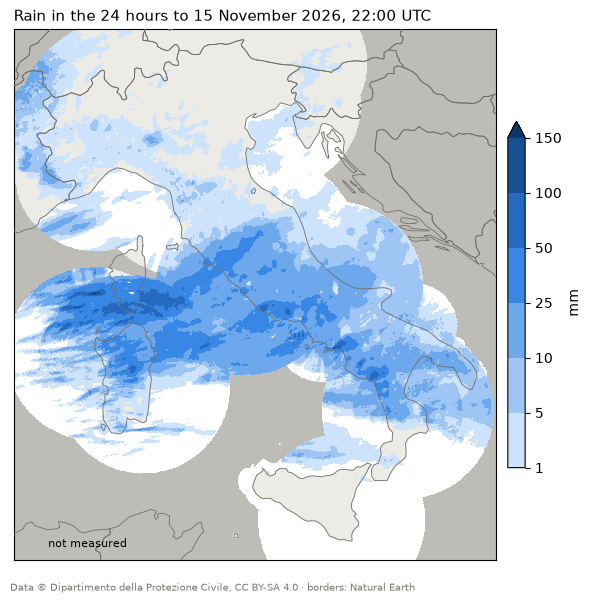

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
rain_map(
    rain,
    ax,
    [1, 5, 10, 25, 50, 100, 150],
    title=f"Rain in the 24 hours to {rain.time:%d %B %Y, %H:%M} UTC",
)
fig.text(0.12, 0.1, CREDIT, fontsize=7, color="#7a7974")
plt.show()

Blue is rain: the darker, the more. The pale land had less than 1 mm. The **grey** area is
where nobody measured: it is outside the reach of the radars. Remember the grey, we come
back to it.

## How much rain on my city?

`sample` takes a list of points as `(longitude, latitude)` and gives one number each. It does
not read a single pixel, which could be a glitch: it takes the **median** of the 3 × 3 pixels
around the point.

In [5]:
cities = {
    "Milano": (9.19, 45.46),
    "Genova": (8.95, 44.41),
    "Roma": (12.50, 41.90),
    "Napoli": (14.27, 40.85),
    "Bari": (16.87, 41.12),
    "Palermo": (13.36, 38.12),
    "Cagliari": (9.12, 39.22),
}
for city, mm in zip(cities, rain.sample(list(cities.values())), strict=True):
    print(f"{city:<10} {mm:6.1f} mm  {'#' * round(mm / 2)}")

Milano        0.0 mm  
Genova        0.0 mm  
Roma         27.0 mm  #############
Napoli       17.7 mm  #########
Bari          3.4 mm  ##
Palermo       0.0 mm  
Cagliari      0.0 mm  


## «No data» is not «no rain»

Ask for a point in the middle of the Atlantic Ocean. The answer is not `0.0`: it is `None`.
The radar never looked there, so the honest answer is *I do not know*. A program that turns
`None` into zero would call «dry» a place it knows nothing about.

In [6]:
[palermo, atlantic] = rain.sample([(13.36, 38.12), (-30.0, 40.0)])
print("Palermo  :", palermo)
print("Atlantic :", atlantic)

measured = np.isfinite(rain.data).mean()
print(f"{measured:.0%} of the pixels of this frame are measured; the rest is grey on the map")

Palermo  : 0.0
Atlantic : None
62% of the pixels of this frame are measured; the rest is grey on the map


## Where did it rain the most?

`peak` looks inside a box `(west, south, east, north)` and returns the highest value and how
many pixels are over a threshold. Each pixel is about one square kilometre, so the count is
also an area.

In [7]:
top, pixels = rain.peak(ITALY, threshold=50.0)
print(f"highest value in the frame : {top:.0f} mm in 24 hours")
print(f"area with 50 mm or more    : about {pixels:,} km²")

highest value in the frame : 166 mm in 24 hours
area with 50 mm or more    : about 10,419 km²


## Right now: how hard is it raining?

`SRI` is the rain **rate**, in millimetres per hour, updated every five minutes. It is radar
only: quick, but less precise than a «Merging». Over 30 mm/h is a violent shower.

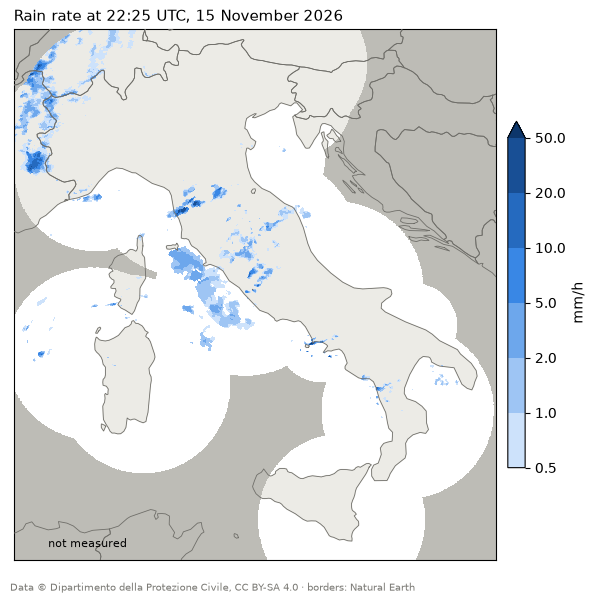

strongest rain now: 83 mm/h; violent showers (30 mm/h or more) on 42 km²


In [8]:
async with RadarClient() as radar:
    now = await radar.latest("SRI")

fig, ax = plt.subplots(figsize=(7.5, 7.5))
rain_map(
    now,
    ax,
    [0.5, 1, 2, 5, 10, 20, 50],
    unit="mm/h",
    title=f"Rain rate at {now.time:%H:%M} UTC, {now.time:%d %B %Y}",
)
fig.text(0.12, 0.1, CREDIT, fontsize=7, color="#7a7974")
plt.show()

top, pixels = now.peak(ITALY, threshold=30.0)
print(f"strongest rain now: {top:.0f} mm/h; violent showers (30 mm/h or more) on {pixels} km²")

## What you have seen

| You wanted | You wrote |
|---|---|
| the latest frame | `await radar.latest("CUM24")` |
| the rain at a place | `rain.sample([(lon, lat)])` |
| the peak in an area | `rain.peak(box, threshold=50)` |
| the rain rate now | `await radar.latest("SRI")` |

**Next:** [2 · Anatomy of a storm](02_anatomy_of_a_storm.ipynb) follows a real flood hour by
hour, and shows how much the radar alone gets wrong.

*Radar data © Dipartimento della Protezione Civile, CC BY-SA 4.0. This notebook is not an
official alert: the alerts that count come from the Civil Protection.*